In [128]:
#%%
# from scipy import optimize
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from qutip import *
from TK_basics import *
import qutip as qt

In [129]:
# data = np.load(r"C:\Users\tanju\Dropbox\PY\20260615_Clara\ideal_cubic_0.npz")
# data = np.load(r"C:\Users\tanju\Dropbox\PY\20260615_Clara\ideal_cubic_p.npz")
# data = np.load(r"C:\Users\tanju\Dropbox\PY\20260615_Clara\ideal_cubic_m.npz")
# data = np.load(r"C:\Users\tanju\Dropbox\PY\20260615_Clara\ideal_quartic_0.npz")
# data = np.load(r"C:\Users\tanju\Dropbox\PY\20260615_Clara\ideal_quartic_p.npz")
# data = np.load(r"C:\Users\tanju\Dropbox\PY\20260615_Clara\ideal_quartic_m.npz")
# data = np.load(r"C:\Users\tanju\Dropbox\PY\20260615_Clara\ideal_mixed_0.npz")
# data = np.load(r"C:\Users\tanju\Dropbox\PY\20260615_Clara\ideal_mixed_p.npz")
# data = np.load(r"C:\Users\tanju\Dropbox\PY\20260615_Clara\ideal_mixed_m.npz")
data = np.load(r"C:\Users\tanju\Dropbox\PY\20260615_Clara\ideal_cubicr_1.npz")
# data = np.load(r"C:\Users\tanju\Dropbox\PY\20260615_Clara\ideal_cubicr_2.npz")
# data = np.load(r"C:\Users\tanju\Dropbox\PY\20260615_Clara\ideal_cubicr_3.npz")

rhoD25 = data["rhoD25"]
rho_ideal=data["rho"]


In [130]:
D = 25#dimension the density matrix to reconstruct

#same list of displacements as in the map code
left = np.linspace(-8.5, -4.6, 20)
middle = np.linspace(-4.5, 4.5, 41)#fixed
right = np.linspace(4.6, 8.5, 20)
al = np.concatenate([left, middle, right])

al_rev = np.flip(al)
AL = []
for m in range(len(al_rev)):
    for n in range(len(al)):
        AL.append(al[n]+1j*al_rev[m])
AL = np.array(AL)
n_dis = len(AL)

xi = 1e-2 #strength for random errors (if needed to add in observables)

RM = 2*n_dis #no of observables, factor of 2 as we have real and imaginary CF
nD = D**2-1 #no of real parameters for general state
Nte = 1 #no of testing state

cdim = 140 #truncation dimension in simulation
a = destroy(cdim).full() #annihilation for cavity

X_r = np.zeros([RM + 1, Nte], dtype = np.complex128) #store readouts
X_r[0,:] = np.ones([1, Nte]) #setting the ones
Y_r = np.zeros([nD, Nte], dtype = np.complex128) #store the targets

In [131]:
#%%Mapping
#upload the map we computed with another code
data = np.load(r"C:\Users\tanju\Dropbox\PY\20260615_Clara\clean_data_reconstruction\map_ideal_D25_reimdiag_CF1mode_grid.npz",'r')
# data = np.load(r"map_ideal_D25_reimdiag_CF1mode_grid.npz",'r')
M = data["M"]
W = data["W"]
beta = data["beta"]

In [132]:
W.shape

(624, 13122)

# DATA LOADING
First block is cubic; second is quartic; third is mixed; fourth is repeated

In [190]:
### CUBIC ###
#############

############################ VACUUM #############################

# directory_name = r"C:\Users\tanju\Dropbox\PY\20260615_Clara\clean_data_reconstruction\cubic"


# data = np.load(rf"{directory_name}\00-19-18_QSP_real_compressed.npz", allow_pickle=True) # cubic


# # # Unpack objects
# averaged_masked_0_real = data["averaged_masked_0"]
# averaged_masked_1_real = data["averaged_masked_1"]

# per_in_g = data["num_in_g"]

# data = np.load(rf"{directory_name}\05-56-23_QSP_imag_compressed.npz", allow_pickle=True) # cubic

# # # Unpack objects
# averaged_masked_0_imag = data["averaged_masked_0"]
# averaged_masked_1_imag = data["averaged_masked_1"]

# per_in_g_im = data["num_in_g"]

# midpoint_re = 0.495
# toppoint_re = 0.946

# midpoint_im = 0.495
# toppoint_im = 0.946

# ############################ ALPHA = 0.5  #############################

# directory_name = r"C:\Users\tanju\Dropbox\PY\20260615_Clara\clean_data_reconstruction\cubic"


# # import pickle


# data = np.load(rf"{directory_name}\23-16-12_QSP_real_alpha-0p5_compressed.npz", allow_pickle=True) # cubic


# # # Unpack objects
# averaged_masked_0_real = data["averaged_masked_0"]
# averaged_masked_1_real = data["averaged_masked_1"]

# per_in_g = data["num_in_g"]

# data = np.load(rf"{directory_name}\02-58-13_QSP_imag_alpha-0p5_compressed.npz", allow_pickle=True) # cubic

# # # Unpack objects
# averaged_masked_0_imag = data["averaged_masked_0"]
# averaged_masked_1_imag = data["averaged_masked_1"]

# per_in_g_im = data["num_in_g"]

# midpoint_re = 0.47
# toppoint_re = 0.8955

# midpoint_im = 0.47
# toppoint_im = 0.8955


# ############################ ALPHA = -0.5  #############################

directory_name = r"C:\Users\tanju\Dropbox\PY\20260615_Clara\clean_data_reconstruction\cubic"


data = np.load(rf"{directory_name}\12-01-37_QSP_real_alpha0p5_compressed.npz", allow_pickle=True) # cubic


# # Unpack objects
averaged_masked_0_real = data["averaged_masked_0"]
averaged_masked_1_real = data["averaged_masked_1"]

per_in_g = data["num_in_g"]

data = np.load(rf"{directory_name}\15-43-37_QSP_imag_alpha0p5_compressed.npz", allow_pickle=True) # cubic

# # Unpack objects
averaged_masked_0_imag = data["averaged_masked_0"]
averaged_masked_1_imag = data["averaged_masked_1"]

per_in_g_im = data["num_in_g"]

midpoint_re = 0.47
toppoint_re = 0.8955

midpoint_im = 0.47
toppoint_im = 0.8955






In [257]:
### QUARTIC ###
#############

############################ VACUUM #############################

# directory_name = r"C:\Users\tanju\Dropbox\PY\20260615_Clara\clean_data_reconstruction\quartic"


# data = np.load(rf"{directory_name}\11-01-20_QSP_real_compressed.npz", allow_pickle=True) # cubic


# # # Unpack objects
# averaged_masked_0_real = data["averaged_masked_0"]
# averaged_masked_1_real = data["averaged_masked_1"]

# per_in_g = data["num_in_g"]

# data = np.load(rf"{directory_name}\22-20-07_QSP_imag_compressed.npz", allow_pickle=True) # cubic

# # # Unpack objects
# averaged_masked_0_imag = data["averaged_masked_0"]
# averaged_masked_1_imag = data["averaged_masked_1"]

# per_in_g_im = data["num_in_g"]

# midpoint_re = 0.478
# toppoint_re = 0.91

# midpoint_im = 0.478
# toppoint_im = 0.91

############################ ALPHA = 0.5 #############################

# import pickle

# directory_name = r"C:\Users\tanju\Dropbox\PY\20260615_Clara\clean_data_reconstruction\quartic"



# data = np.load(rf"{directory_name}\01-04-03_QSP_real_m0p5_compressed.npz", allow_pickle=True) # cubic


# # # Unpack objects
# averaged_masked_0_real = data["averaged_masked_0"]
# averaged_masked_1_real = data["averaged_masked_1"]

# per_in_g = data["num_in_g"]

# data = np.load(rf"{directory_name}\04-46-04_QSP_imag_m0p5_compressed.npz", allow_pickle=True) # cubic

# # # Unpack objects
# averaged_masked_0_imag = data["averaged_masked_0"]
# averaged_masked_1_imag = data["averaged_masked_1"]

# per_in_g_im = data["num_in_g"]


# midpoint_re = 0.5
# toppoint_re = 0.9482

# midpoint_im = 0.5
# toppoint_im = 0.9482


############################ ALPHA = -0.5 #############################



import pickle

directory_name = r"C:\Users\tanju\Dropbox\PY\20260615_Clara\clean_data_reconstruction\quartic"



data = np.load(rf"{directory_name}\10-40-32_QSP_real_0p5_compressed.npz", allow_pickle=True) # cubic


# # Unpack objects
averaged_masked_0_real = data["averaged_masked_0"]
averaged_masked_1_real = data["averaged_masked_1"]

per_in_g = data["num_in_g"]

data = np.load(rf"{directory_name}\14-26-24_QSP_imag_0p5_compressed.npz", allow_pickle=True) # cubic

# # Unpack objects
averaged_masked_0_imag = data["averaged_masked_0"]
averaged_masked_1_imag = data["averaged_masked_1"]

per_in_g_im = data["num_in_g"]



midpoint_re = 0.5
toppoint_re = 0.9482

midpoint_im = 0.5
toppoint_im = 0.9482



In [323]:
### MIXED ###
#############

############################ VACUUM #############################

# import pickle

# directory_name = r"C:\Users\tanju\Dropbox\PY\20260615_Clara\clean_data_reconstruction\mixed"


# data = np.load(rf"{directory_name}\10-16-04_QSP_real_compressed.npz", allow_pickle=True) # cubic


# # # Unpack objects
# averaged_masked_0_real = data["averaged_masked_0"]
# averaged_masked_1_real = data["averaged_masked_1"]

# per_in_g = data["num_in_g"]

# data = np.load(rf"{directory_name}\13-59-22_QSP_imag_compressed.npz", allow_pickle=True) # cubic

# # # Unpack objects
# averaged_masked_0_imag = data["averaged_masked_0"]
# averaged_masked_1_imag = data["averaged_masked_1"]

# per_in_g_im = data["num_in_g"]

# midpoint_re = 0.495
# toppoint_re = 0.9488

# midpoint_im = 0.495
# toppoint_im = 0.9488

############################ ALPHA = 0.5 #############################
# import pickle

# directory_name = r"C:\Users\tanju\Dropbox\PY\20260615_Clara\clean_data_reconstruction\mixed"


# data = np.load(rf"{directory_name}\10-28-08_QSP_real_m0p5_compressed.npz", allow_pickle=True) # cubic


# # # Unpack objects
# averaged_masked_0_real = data["averaged_masked_0"]
# averaged_masked_1_real = data["averaged_masked_1"]

# per_in_g = data["num_in_g"]

# data = np.load(rf"{directory_name}\14-10-10_QSP_imag_m0p5_compressed.npz", allow_pickle=True) # cubic

# # # Unpack objects
# averaged_masked_0_imag = data["averaged_masked_0"]
# averaged_masked_1_imag = data["averaged_masked_1"]

# per_in_g_im = data["num_in_g"]

# midpoint_re = 0.5
# toppoint_re = 0.9458

# midpoint_im = 0.5
# toppoint_im = 0.9458


############################ ALPHA = -0.5 #############################

import pickle

directory_name = r"C:\Users\tanju\Dropbox\PY\20260615_Clara\clean_data_reconstruction\mixed"



data = np.load(rf"{directory_name}\10-10-45_QSP_real_0p5_compressed.npz", allow_pickle=True) # cubic


# # Unpack objects
averaged_masked_0_real = data["averaged_masked_0"]
averaged_masked_1_real = data["averaged_masked_1"]

per_in_g = data["num_in_g"]

data = np.load(rf"{directory_name}\13-52-47_QSP_imag_0p5_compressed.npz", allow_pickle=True) # cubic

# # Unpack objects
averaged_masked_0_imag = data["averaged_masked_0"]
averaged_masked_1_imag = data["averaged_masked_1"]

per_in_g_im = data["num_in_g"]

midpoint_re = 0.495
toppoint_re = 0.9485

midpoint_im = 0.495
toppoint_im = 0.9485





In [ ]:
### REPEATED CUBIC ###
######################



############################ 1 GATE ################################
import pickle

directory_name = r"C:\Users\tanju\Dropbox\PY\20260615_Clara\clean_data_reconstruction\repeated_cubic\1_gates"


data = np.load(rf"{directory_name}\00-42-25_QSP_real_compressed.npz", allow_pickle=True) # cubic



# # Unpack objects
averaged_masked_0_real = data["averaged_masked_0"]
averaged_masked_1_real = data["averaged_masked_1"]

per_in_g = data["num_in_g"]

data = np.load(rf"{directory_name}\04-24-14_QSP_imag_compressed.npz", allow_pickle=True) # cubic

# # Unpack objects
averaged_masked_0_imag = data["averaged_masked_0"]
averaged_masked_1_imag = data["averaged_masked_1"]

per_in_g_im = data["num_in_g"]

midpoint_re = 0.469
toppoint_re = 0.898

midpoint_im = 0.469
toppoint_im = 0.898

############################ 2 GATE ################################

# import pickle

# directory_name = r"C:\Users\tanju\Dropbox\PY\20260615_Clara\clean_data_reconstruction\repeated_cubic\2_gates"



# data = np.load(rf"{directory_name}\11-41-01_QSP_real_compressed.npz", allow_pickle=True) # cubic


# # # Unpack objects
# averaged_masked_0_real = data["averaged_masked_0"]
# averaged_masked_1_real = data["averaged_masked_1"]

# per_in_g = data["num_in_g"]

# data = np.load(rf"{directory_name}\15-32-56_QSP_imag_compressed.npz", allow_pickle=True) # cubic

# # # Unpack objects
# averaged_masked_0_imag = data["averaged_masked_0"]
# averaged_masked_1_imag = data["averaged_masked_1"]

# per_in_g_im = data["num_in_g"]

# midpoint_re = 0.468
# toppoint_re = 0.885

# midpoint_im = 0.468
# toppoint_im = 0.885


############################ 3 GATE ################################
# import pickle

# directory_name = r"C:\Users\tanju\Dropbox\PY\20260615_Clara\clean_data_reconstruction\repeated_cubic\3_gates"

# data = np.load(rf"{directory_name}\20-53-50_QSP_real_compressed.npz", allow_pickle=True) # cubic


# # # Unpack objects
# averaged_masked_0_real = data["averaged_masked_0"]
# averaged_masked_1_real = data["averaged_masked_1"]

# per_in_g = data["num_in_g"]

# data = np.load(rf"{directory_name}\00-36-08_QSP_imag_compressed.npz", allow_pickle=True) # cubic

# # # Unpack objects
# averaged_masked_0_imag = data["averaged_masked_0"]
# averaged_masked_1_imag = data["averaged_masked_1"]

# per_in_g_im = data["num_in_g"]


# midpoint_re = 0.468
# toppoint_re = 0.8934

# midpoint_im = 0.468
# toppoint_im = 0.8934





In [114]:

print(f"percent in g: {per_in_g}")

# print(f"max of CF_re in the data used to scale data= {np.max(CF_re_raw)}")
CF_re_scaled = (averaged_masked_0_real - midpoint_re) / (toppoint_re-midpoint_re)
CF_im_scaled = (averaged_masked_0_imag - midpoint_im) / (toppoint_im-midpoint_im)

print(CF_re_scaled.shape)

print(np.max(CF_re_scaled))

# np.savez(
#     f"{directory_name}/data/cubic and quartic/alpha_0p5.npz",
#     per_in_g_re = per_in_g,
#     per_in_g_im = per_in_g_im,    
#     CF_re_scaled = CF_re_scaled,
#     CF_im_scaled = CF_im_scaled,
# )



percent in g: 0.7686940680517916
(27, 41)
1.0001771654405942


Text(0.5, 0.98, '%g = 0.768, midpoint=0.468, toppoint=0.8934\n\n')

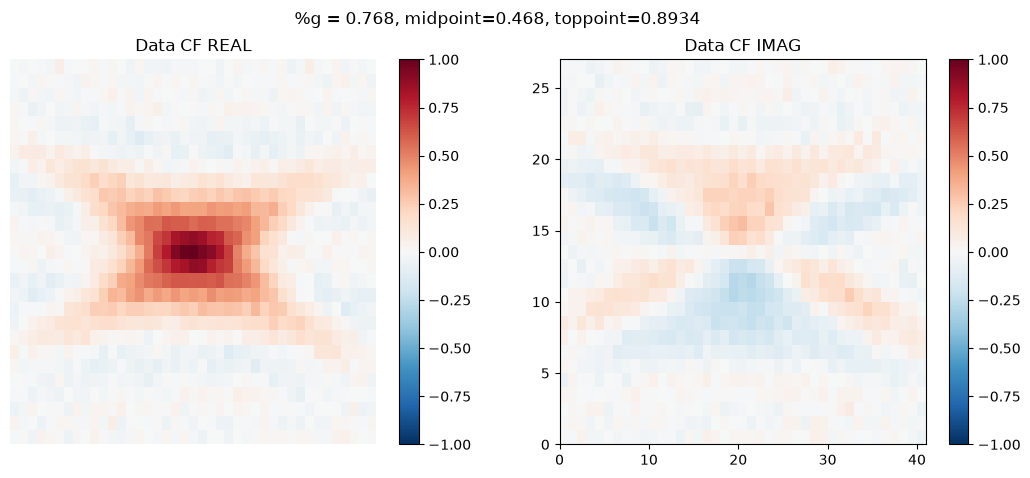

In [115]:
plt.figure(figsize=(13, 5))
plt.subplot(121)

c = plt.pcolormesh(CF_re_scaled, cmap='RdBu_r', vmin=-1.0, vmax=1.0)
plt.colorbar(c)
plt.axis('off')
plt.title("Data CF REAL")

plt.subplot(122)
c = plt.pcolormesh(CF_im_scaled, cmap='RdBu_r', vmin=-1, vmax=1.0)
plt.colorbar(c)
plt.title("Data CF IMAG")

plt.suptitle(f"%g = {((per_in_g+per_in_g_im)/2):.3f}, midpoint={midpoint_re}, toppoint={toppoint_re}\n\n")

In [116]:
from matplotlib.colors import LinearSegmentedColormap

pink_green = LinearSegmentedColormap.from_list(
    "pink_green",
    [
        "#63AF00",  # dark green
        "#FFFFFF",  # white (center)
        "#900032", 
    ],
    N=256,
)

pink_green_r = LinearSegmentedColormap.from_list(
    "pink_green_r",
    [
         # dark green
          # white (center)
        "#900032", 
        "#FFFFFF",
        "#63AF00", 
    ],
    N=256,
)
from matplotlib.colors import TwoSlopeNorm

norm = TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1)

In [117]:
# plt.close('all')
# plt.figure(figsize=(13, 13))

# c = plt.pcolormesh(CF_im_scaled, cmap=pink_green_r, vmin=-1.0, vmax=1.0)

# # cbar = plt.colorbar(c)
# # cbar.set_ticks([]) 

# plt.axis('off')
# plt.savefig(f'{directory_name}/plots/reconstructed/cubic_throw_im_light_PG.png', dpi=600, bbox_inches='tight')


In [118]:
# CF_re_padded = np.pad(
#     CF_re_scaled,
#     pad_width=((20, 20), (20, 20)),
#     mode='constant',
#     constant_values=0
# )

# CF_im_padded = np.pad(
#     CF_im_scaled,
#     pad_width=((20, 20), (20, 20)),
#     mode='constant',
#     constant_values=0
# )

CF_re_padded = np.pad(
    CF_re_scaled,
    pad_width=((27, 27), (20, 20)),
    mode='constant',
    constant_values=0
)

CF_im_padded = np.pad(
    CF_im_scaled,
    pad_width=((27, 27), (20, 20)),
    mode='constant',
    constant_values=0
)

print(CF_re_padded.shape)  # (81, 81)
print(CF_im_padded.shape)  # (81, 81)

(81, 81)
(81, 81)


Text(0.5, 1.0, 'Data CF IMAG')

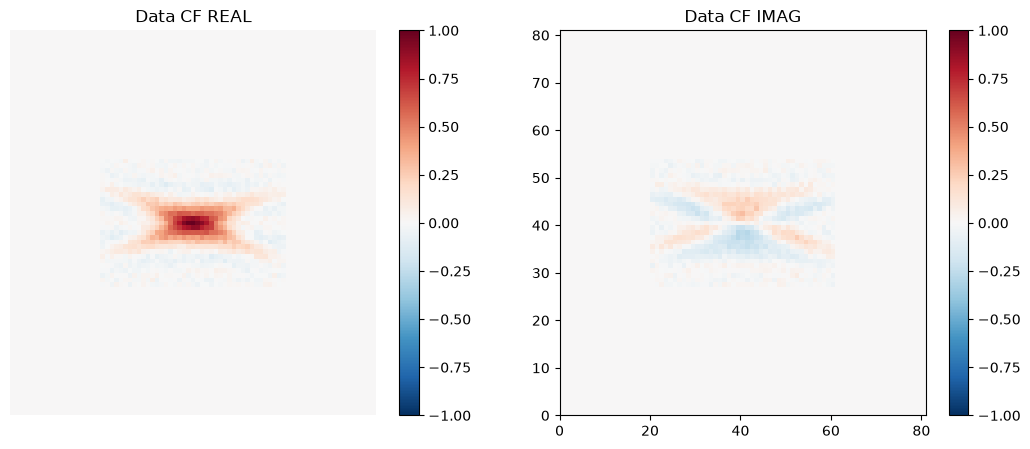

In [119]:
plt.figure(figsize=(13, 5))
plt.subplot(121)

c = plt.pcolormesh(CF_re_padded, cmap='RdBu_r', vmin=-1.0, vmax=1.0)
plt.colorbar(c)
plt.axis('off')
plt.title("Data CF REAL")

plt.subplot(122)
c = plt.pcolormesh(CF_im_padded, cmap='RdBu_r', vmin=-1, vmax=1.0)
plt.colorbar(c)
plt.title("Data CF IMAG")

# plt.suptitle(f"%g = {((per_in_g+per_in_g_im)/2):.3f}, midpoint={midpoint_re}, toppoint={toppoint_re}\n\n")

In [120]:
X_r[1:n_dis+1, 0] = CF_re_padded.flatten()
X_r[n_dis+1:, 0] = CF_im_padded.flatten()


In [121]:
n_obs = beta.shape[0]
C = np.matmul(-W, beta[:, 0])
BETA = np.zeros([nD, n_obs + 1], dtype=np.complex128)
BETA[:, 0] = C
BETA[:, 1 : n_obs + 1] = W
Y_est = np.matmul(BETA, X_r)

#now we get the density matrix for Y_est
r_est = np.zeros((D, D), dtype=complex)

cw = 0
# diagonal elements
for j1 in np.arange(0, D-1):
    r_est[j1, j1] = Y_est[cw, 0]
    cw += 1
r_est[D-1,D-1] = 1 - np.trace(r_est)
# off-diagonal elements
for j1 in np.arange(0, D-1):
    for j2 in np.arange(j1+1, D):
        real_part = Y_est[cw, 0]
        cw += 1
        imag_part = Y_est[cw, 0]
        cw += 1
        r_est[j1, j2] = real_part + 1j * imag_part
        r_est[j2, j1] = real_part - 1j * imag_part  # Hermitian conjugate

#density matrix, just linear inversion with trace 1 condition imposed
qRho_est = Qobj(r_est)

#density matrix, maximum likelihood
qRho_est = PSD_rho(qRho_est.full())

phi_correction = 0.5* np.pi  # rotation angle

U_rot = (-1j * phi_correction * qt.num(D)).expm()
rho_rot = (U_rot * qRho_est * U_rot.dag()).conj()

# #we expand rho_rot to D250
N = 250
rho_rot250 = np.zeros([N,N], dtype=np.complex128)
rho_rot250[0:25,0:25] = rho_rot.full()

#density matrix, Bayesian inference, takes more time 
Nrep = 1000#number of experimental repetitions 
Fmean, Fstd, qRho_est = Bysn_rho_v2(2**10, Nrep*(nD), rhoD25, rho_rot.full())
# Fmean, Fstd, qRho_est = Bysn_rho_v2(2**10, Nrep*(nD), rho_ideal, rho_rot250)




In [122]:
rho_ideal.shape

(250, 250)

In [124]:
print(f'trace is {qRho_est.tr()}')

print(f'FidelityD25 is {fidelity(Qobj(rhoD25), qRho_est)**2}')
print(f'FidelityBI is {Fmean} +- {Fstd}')

#expanding the reconstructed state to N = 250
N = rho_ideal.shape[0]
rho = np.zeros([N,N], dtype=np.complex128)
rho[0:25,0:25] = qRho_est.full()
print(f'Fidelity250 is {fidelity(Qobj(rho_ideal), Qobj(rho))**2}')

# print(f'FidelityD250 is {fidelity(Qobj(rho_ideal), qRho_est)**2}')
# print(f'FidelityBI is {Fmean} +- {Fstd}')


trace is 0.9999999999999997
FidelityD25 is 0.8770248954288475
FidelityBI is 0.8770249115945146 +- 0.03745742576932368
Fidelity250 is 0.8711806286258396


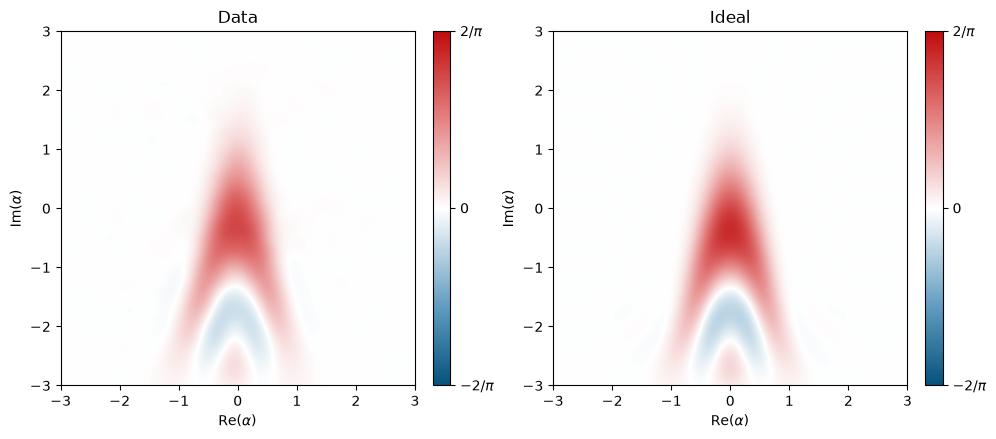

In [125]:
import dynamiqs as dq

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

dq.plot.wigner(
    qRho_est.data_as('ndarray'),
    xmax=3, ymax=3,
    ax=axes[0]
)
axes[0].set_title(
    f"Data"
)

dq.plot.wigner(
    rhoD25,
    xmax=3, ymax=3,
    ax=axes[1]
)
axes[1].set_title("Ideal")

plt.tight_layout()

In [126]:
# xvec = np.linspace(-8,8,401)
# yvec = np.linspace(-8,8,401)

# xx,yy,ww = dq.wigner(rhoD25,xvec=xvec,yvec=yvec,npixels=401)
# dx = xx[1]-xx[0]
# dy = yy[1]-yy[0]

# neg = (np.sum(np.abs(ww))*dx*dy-1)/2
# print(f'neg_id is {neg}')

# xx,yy,ww = dq.wigner(qRho_est,xvec=xvec,yvec=yvec,npixels=401)
# neg = (np.sum(np.abs(ww))*dx*dy-1)/2
# print(f'neg_exp is {neg}')

xvec = np.linspace(-8,8,401)
yvec = np.linspace(-8,8,401)
vm = 8
neg = wigner_negv2(rhoD25, 401, beta=np.array([-vm,vm,-vm,vm]))
print(f'neg_id {neg}')
neg = wigner_negv2(qRho_est.full(), 401, beta=np.array([-vm,vm,-vm,vm]))
print(f'neg_exp {neg}')


neg_id 0.11446154833704325
neg_exp 0.09518952766325672


In [127]:
#wigner neg with BI
Nrep = 1000#number of experimental repetitions 
neg_mean, neg_std, qRho_est = Bysn_rho_WN(2**10, Nrep*(nD), rho_rot.full())
print(f'neg is {neg_mean} +- {neg_std}')
print(f'error percent {neg_std/neg_mean*100}%')

neg is 0.10428564584521287 +- 0.021289568697048525
error percent 20.414668312691667%


In [ ]:
# np.savez(
#     "reconstructed_cubic_0p0.npz",
#     ideal_rho=rhoD25,
#     reconstructed_rho=rho_rot,
#     F=fidelity(Qobj(rhoD25), rho_rot)
# )